# 02 Periodograms

This notebook produces results that are described in Section 4, including Table 2 and Figures 2–4:

* the Lomb–Scargle periodogram of the full T Tau light curve and its spectral window 
* the sliding-window periodogram 
* the local periodogram of the strongest episode, MJD 56742–56915 
* a calibration check: the same sliding analysis on the calibrator data 

Note: False-alarm probabilities (FAPs) reported here are the analytic white-noise values. Red-noise analysis of FAP values is in notebook 3.

In [1]:
import numpy as np
import pandas as pd
import pylab as pl
from astropy.timeseries import LombScargle

In [2]:
def clip_bursts(t, y, dy, nsig):
    """
    Iteratively remove points > nsig robust sigmas from the median
    (e.g. accretion bursts / flares that dominate a periodogram).
    """
    
    keep = np.ones_like(y, bool)
    for _ in range(5):
        med = np.median(y[keep])
        mad = 1.4826 * np.median(np.abs(y[keep] - med))
        new = np.abs(y - med) < nsig * mad
        if (new == keep).all():
            break
        keep = new
    return t[keep], y[keep], dy[keep], (~keep).sum()

In [3]:
CLIP = 4.0

data = pd.read_csv('TTau-2011-15A+O.csv')
tc, yc, dyc, nclip = clip_bursts(data.MJD, data.flux, data.error, CLIP)

baseline = np.ptp(data.MJD) # get the range of dates
freq = np.arange(1 / (baseline / 2), 1.0, 1 / (10 * baseline))   # 1 day to baseline/2, oversampled x10


---
## Calculate the full T Tau light curve

In [4]:
def top_peaks(f, p, ls, n=5):
    
    """
    Strongest distinct local maxima (separated by > 2/baseline)
    f : frequencies
    p : L-S power
    ls: periodogram (output from astropy LombScargle)
    n : number of peaks
    """
    
    out = []
    for i in np.argsort(p)[::-1]:
        
        if all(abs(f[i] - o[1]) > 2 / baseline for o in out):
            
            # calculate FAP:
            fap = ls.false_alarm_probability(p[i], minimum_frequency=f[0], maximum_frequency=f[-1])
            out.append((1 / f[i], f[i], p[i], fap))
        
        if len(out) == n:
            break
            
    return pd.DataFrame(out, columns=["P_d", "freq", "power", "FAP"])

for label, (tt, yy, ee) in {"all points": (data.MJD, data.flux, data.error), "bursts clipped": (tc, yc, dyc)}.items():
    ls = LombScargle(tt, yy, ee) # call L-S from astropy
    display(top_peaks(freq, ls.power(freq), ls).round(4).style.set_caption(label))

,P_d,freq,power,FAP
0,258.398200,0.003900,0.051000,0.326800
1,3.507100,0.285100,0.048900,0.435500
2,1.001500,0.998500,0.048600,0.453100
3,1.009000,0.991100,0.045400,0.651700
4,1.058200,0.945000,0.043800,0.748500


,P_d,freq,power,FAP
0,253.864900,0.003900,0.051100,0.365300
1,3.509700,0.284900,0.050500,0.398700
2,1.029400,0.971400,0.046400,0.642300
3,1.058100,0.945100,0.045400,0.704600
4,31.943300,0.031300,0.045200,0.717200


### Make Figure 1

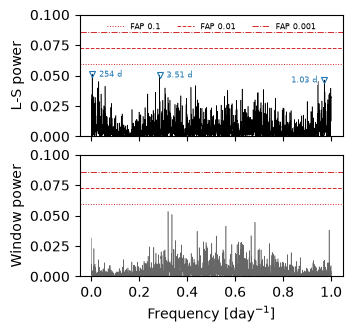

In [5]:
# plotting parameters
COL_W, PAGE_W = 3.4, 7.0 
YLIM = (0, 0.1)   

# make L-S for target data
ls = LombScargle(tc, yc, dyc)
p = ls.power(freq)

# make L-S for window (noise)
win = LombScargle(tc, np.ones_like(tc), fit_mean=False, center_data=False).power(freq)

fig, ax = pl.subplots(2, 1, figsize=(COL_W, 3.4), sharex=True, gridspec_kw=dict(hspace=0.15))

# display FAP=0.1, 0.01, 0.001 levels:
fap_levels = {fap: ls.false_alarm_level(fap, minimum_frequency=freq[0], maximum_frequency=freq[-1])
              for fap in [0.1, 0.01, 0.001]}

ax[0].plot(freq, p, "k", lw=0.4)
ax[1].plot(freq, win, color="0.4", lw=0.4)

# data-periodogram FAP levels drawn in both panels for reference
for a in ax:   
    for (fap, lvl), s in zip(fap_levels.items(), [":", "--", "-."]):
        a.axhline(lvl, color="C3", ls=s, lw=0.7, label=f"FAP {fap:g}")
        
# three highest distinct peaks of the plotted (burst-clipped) periodogram
peaks3 = top_peaks(freq, p, ls, n=3)
ax[0].plot(peaks3.freq, peaks3.power, "v", ms=4, mfc="none", mec="C0", mew=0.8, zorder=5)
for _, r in peaks3.iterrows():
    # label beside the marker, centred on the peak height, so it stays below the FAP lines;
    # labels near the right-hand edge go on the left of the marker
    dx, ha = (-5, "right") if r.freq > 0.9 else (5, "left")
    ax[0].annotate(f"{r.P_d:.3g} d", (r.freq, r.power), xytext=(dx, 0), textcoords="offset points",
                   ha=ha, va="center", fontsize=6, color="C0",
                   bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.8))

ax[0].legend(frameon=False, fontsize=6, loc="upper center", ncol=3)
ax[0].set(ylabel="L-S power", ylim=YLIM)
ax[1].set(ylabel="Window power", xlabel="Frequency [day$^{-1}$]", ylim=YLIM)

fig.savefig("global_ls.png")
pl.show()

---
## Sliding-window periodogram (Section 4.2)


In [6]:
class SlidingLS:
    def __init__(self, t, dy, width, step, pmin, pmax, nper, nmin, detrend):
        self.t, self.dy = t, dy
        self.periods = np.geomspace(pmin, pmax, nper)
        self.freq = 1.0 / self.periods
        self.centres = np.arange(t.min() + width / 2, t.max() - width / 2 + 1e-9, step)
        self.masks = [np.abs(t - c) <= width / 2 for c in self.centres]
        self.ok = np.array([m.sum() >= nmin for m in self.masks])
        self.detrend = detrend

    def power_map(self, y):
        pmap = np.full((len(self.periods), len(self.centres)), np.nan)
        for j, m in enumerate(self.masks):
            if not self.ok[j]:
                continue
            tw, yw, dw = self.t[m], y[m], self.dy[m]
            if self.detrend >= 0:
                x = tw - tw.mean()
                yw = yw - np.polyval(np.polyfit(x, yw, self.detrend, w=1 / dw), x)
            pmap[:, j] = LombScargle(tw, yw, dw).power(self.freq, method="cython")
        return pmap

In [7]:
def sliding(tt, yy, ee, width):
    
    """
    Power map plus a per-window table of the best peak and its analytic FAP.
    """
    
    S = SlidingLS(tt, ee, width, STEP, PMIN, PMAX, NPER, NMIN, 1)
    
    pm = S.power_map(yy)
    
    rows = []
    for j, c in enumerate(S.centres):
        
        if not S.ok[j]:
            continue
            
        m = S.masks[j]
        tw, yw, ew = tt[m], yy[m], ee[m]
        x = tw - tw.mean()
        yw = yw - np.polyval(np.polyfit(x, yw, 1, w=1 / ew), x)
        k = np.nanargmax(pm[:, j])
        fap = LombScargle(tw, yw, ew).false_alarm_probability(
            pm[k, j], minimum_frequency=1 / PMAX, maximum_frequency=1 / PMIN)
        rows.append((c, m.sum(), S.periods[k], pm[k, j], fap))
        
    return S, pm, pd.DataFrame(rows, columns=["centre", "n", "period", "power", "FAP"])

In [8]:
WIDTH, STEP = 150.0, 10.0  # sliding window width and step [d]
PMIN, PMAX = 2.0, 80.0     # sliding-window period range [d]
NPER, NMIN = 600, 25       # periods on the log grid; min points per window

curves={}
for w in [100, 150, 200]:
    curves[w] = sliding(tc, yc, dyc, w) # using flare clipped data

summary = []
for w, (_, _, tab) in curves.items():
    i = tab.FAP.idxmin()
    summary.append(dict(width=w, n_windows=len(tab), n_FAP_lt_1e2=(tab.FAP < 1e-2).sum(),
                        min_FAP=tab.FAP[i], at_centre=tab.centre[i], P=tab.period[i], power=tab.power[i]))

pd.DataFrame(summary).round(3)

,width,n_windows,n_FAP_lt_1e2,min_FAP,at_centre,P,power
0,100,91,15,0.0,56795.354,49.791,0.679
1,150,119,17,0.0,56820.354,54.274,0.578
2,200,121,17,0.0,56855.354,60.264,0.431


Windows of the calibrated light curve with analytic FAP < 0.01 (150-d windows):

In [9]:
S150, pm150, tab150 = curves[150]
tab150[tab150.FAP < 1e-2].round(4)

,centre,n,period,power,FAP
58,56540.3541,39,30.6097,0.4884,0.0018
59,56550.3541,40,30.4218,0.4671,0.0029
60,56560.3541,38,30.6097,0.5700,0.0001
61,56570.3541,39,31.3731,0.4571,0.0049
62,56580.3541,38,32.5540,0.4466,0.0092
69,56650.3541,37,19.6468,0.4898,0.0034
70,56660.3541,36,19.5261,0.5290,0.0013
84,56800.3541,43,51.6650,0.5162,0.0002
85,56810.3541,44,53.2806,0.4997,0.0003
86,56820.3541,45,54.2741,0.5785,0.0000


#### Make Figure 3

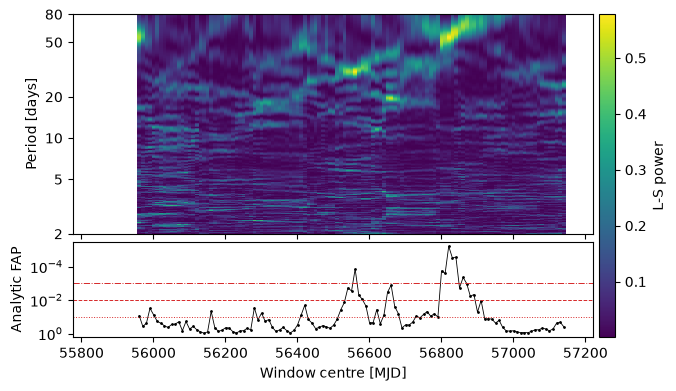

In [10]:
fig, ax = pl.subplots(2, 1, figsize=(PAGE_W, 4.2), sharex=True,
                       gridspec_kw=dict(hspace=0.05, height_ratios=[2.3, 1]))

im = ax[0].pcolormesh(S150.centres, S150.periods, pm150, shading="nearest", cmap="viridis", rasterized=True)
ax[0].set_yscale("log")
ax[0].set_yticks([2, 5, 10, 20, 50, 80]); ax[0].set_yticklabels(["2", "5", "10", "20", "50", "80"])
ax[0].minorticks_off(); ax[0].set_ylabel("Period [days]")

fig.colorbar(im, ax=ax, pad=0.01, fraction=0.03).set_label("L-S power")
fap_all = pd.Series(np.nan, index=S150.centres); fap_all[tab150.centre.values] = tab150.FAP.values
ax[1].semilogy(S150.centres, fap_all.values, "k.-", lw=0.6, ms=2)

for lvl, s in zip([0.1, 0.01, 0.001], [":", "--", "-."]):
    ax[1].axhline(lvl, color="C3", ls=s, lw=0.7)

ax[1].invert_yaxis()
ax[1].set(ylabel="Analytic FAP", xlabel="Window centre [MJD]", xlim=(tc.min(), tc.max()))

fig.savefig("sliding_ls.png", dpi=300)
pl.show()

---
## Check calibrator 

In [11]:
episodes = [(56520, 56600), (56640, 56680), (56790, 56900)]

cal = pd.read_csv('TTAU-with-cal.csv')
tc, yc, dyc, nclip = clip_bursts(cal.MJD, cal.Scal, cal.dScal, CLIP)

curves={}
for w in [100, 150, 200]:
    curves[w] = sliding(tc, yc, dyc, w) # using flare clipped data

rows = []
for lo, hi in episodes:
    row = {"interval": f"{lo}-{hi}"}
    tab = curves[150][2]
    s = tab[(tab.centre >= lo) & (tab.centre <= hi)]
    i = s.FAP.idxmin()
    row.update({f"Scal centre": s.centre[i], f"Scal period": round(s.period[i], 1),
                    f"Scal power": round(s.power[i], 2), f"Scal FAP": f"{s.FAP[i]:.1e}"})
    rows.append(row)
    
pd.DataFrame(rows).set_index("interval").T

interval,56520-56600,56640-56680,56790-56900
Scal centre,56520.3541,56670.3541,56830.3541
Scal period,41.9,7.7,2.3
Scal power,0.38,0.36,0.33
Scal FAP,2.7e-02,1.1e-01,7.4e-02


Calibrator windows with FAP < 0.01 for each window width:

In [12]:
for w in [100, 150, 200]:
    tab = curves[w][2]
    print(f"W = {w} d:"); display(tab[tab.FAP < 1e-2].round(4))

W = 100 d:


,centre,n,period,power,FAP
47,56585.3541,27,35.4853,0.608,0.0028


W = 150 d:


,centre,n,period,power,FAP


W = 200 d:


,centre,n,period,power,FAP


---
### Local analysis for MJD 56742–56915

In [13]:
# load data from localised time period
def load(path, tmin=None, tmax=None):
    df = pd.read_csv(path).dropna(subset=["MJD", "flux", "error"])
    df = df[df["error"] > 0].sort_values("MJD")
    if tmin is not None:
        df = df[df["MJD"] >= tmin]
    if tmax is not None:
        df = df[df["MJD"] <= tmax]
    return df["MJD"].to_numpy(), df["flux"].to_numpy(), df["error"].to_numpy()

In [14]:
tl, yl, el = load('TTau-2011-15A+O.csv', 56742, 56915)
tl, yl, el, ncl = clip_bursts(tl, yl, el, CLIP)

# detrend the data by subtracting a linear fit:
x = tl - tl.mean()
yl = yl - np.polyval(np.polyfit(x, yl, 1, w=1 / el), x) + np.median(yl)

# do the local L-S
fr = np.arange(1 / 90, 1 / 2, 1 / (10 * np.ptp(tl)))
L = LombScargle(tl, yl, el)
pw = L.power(fr)

# make phase plot:
fb = fr[np.argmax(pw)]
theta = L.model_parameters(fb)
amp = np.hypot(theta[1], theta[2])

# print top 3 peaks:
print(f"N = {len(tl)} ({ncl} clipped)")
ord_ = [i for i in np.argsort(pw)[::-1] if 0 < i < len(pw) - 1 and pw[i] > pw[i-1] and pw[i] > pw[i+1]][:3]
for i in ord_:
    print(f"P = {1/fr[i]:6.2f} d  power = {pw[i]:.3f}  FAP = "
          f"{L.false_alarm_probability(pw[i], minimum_frequency=fr[0], maximum_frequency=fr[-1]):.1e}")

# print amplitude of oscillation for most significant peak:
print(f"semi-amplitude = {1e3*amp:.2f} mJy ({amp/np.median(yl):.1%} of median); "
      f"{np.ptp(tl)*fb:.1f} cycles in the window")

N = 52 (1 clipped)
P =  54.74 d  power = 0.474  FAP = 6.6e-05
P =  41.27 d  power = 0.238  FAP = 2.9e-01
P =   5.93 d  power = 0.182  FAP = 8.0e-01
semi-amplitude = 1.06 mJy (12.8% of median); 3.1 cycles in the window


#### Make figure 4

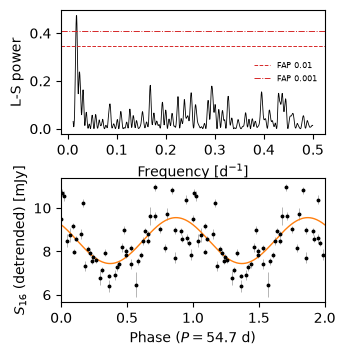

In [15]:
fig, ax = pl.subplots(2, 1, figsize=(COL_W, 3.8), gridspec_kw=dict(hspace=0.35))

ax[0].plot(fr, pw, "k", lw=0.6)

for fap, s in zip([0.01, 0.001], ["--", "-."]):
    ax[0].axhline(L.false_alarm_level(fap, minimum_frequency=fr[0], maximum_frequency=fr[-1]),
                  color="C3", ls=s, lw=0.7, label=f"FAP {fap:g}")

ax[0].set(xlabel="Frequency [d$^{-1}$]", ylabel="L-S power")
ax[0].legend(frameon=False, fontsize=6)
ph = ((tl - tl.min()) * fb) % 1

for o in [0, 1]:
    ax[1].errorbar(ph + o, 1e3 * yl, 1e3 * el, fmt="o", ms=1.8, color="k", ecolor="0.6", lw=0.5)

pp = np.linspace(0, 2, 300)
ax[1].plot(pp, 1e3 * L.model(tl.min() + pp / fb, fb), "C1", lw=1)
ax[1].set(xlim=(0, 2), xlabel=f"Phase ($P={1/fb:.1f}$ d)", ylabel="$S_{16}$ (detrended) [mJy]")

fig.savefig("local_ls.png")
pl.show()